# Text Preprocessing, Feature Engineering, Cursory Analysis

**Objective:** Conduct data engineering steps to convert unstructured clinical text data into clean, structured features for modeling.

---
---
---

## 1. Setup

---

In [ ]:
# Data Management
import json
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text Processing
import re
import string
from symspellpy import SymSpell, Verbosity

# Utils
from IPython.display import display, HTML, IFrame, Image
from pathlib import Path
import random
from random import choice, choices, randint, randrange, sample, shuffle

# Settings
pd.set_option('display.max_columns', None)
pd.set_option('mode.chained_assignment', None)
sns.set_style('darkgrid', {'grid.color':'0.9','xtick.bottom':True,'ytick.left':True})

In [2]:
# Define project root and file paths relative to user OS
BASE_DIR = Path.cwd()
SYNTHETIC_PATIENT_DATA_PATH = BASE_DIR / 'pickled_objects' / 'pt_visit_records.pkl'
SYMSPELLPY_DICT = BASE_DIR / 'simulated_data/' / 'text_data' / 'frequency_dictionary_en_82_765.txt'

In [3]:
# Load the previously assembled patient visit records
pt_visit_records = pd.read_pickle(SYNTHETIC_PATIENT_DATA_PATH)
pt_visit_records.head()

,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin..."
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....


---
---
## 2: Data Preprocessing: Text Normalization

**Objective:** Transform text into clean sentences to prepare for feature engineering.

---

#### 2a: Design helper modules to perform cleaning workflow.

In [4]:
# Initialize spell checker
sym_spell = SymSpell(
    max_dictionary_edit_distance=2,
    prefix_length=7
)

# Define edge-case medical terms most likely not in dictionary
PROTECTED_WORDS = {
    'covid',
    'covid-19',
    'covid-positive',
    'ecg',
    'uti',
    'a1c',
    'pcr',
    'cbc',
    'ct',
    'iv',
    'x-ray',
    'flu'
}

# Define map for UK to US version
UK_TO_US_SPELLING = {
    # General medical terms
    'diarrhoea': 'diarrhea',
    'anaemia': 'anemia',
    'oedema': 'edema',
    'paediatric': 'pediatric',
    'foetal': 'fetal',
    'haemoglobin': 'hemoglobin',
    'haematology': 'hematology',
    'haematological': 'hematological',

    # Diagnostics / testing
    'leukaemia': 'leukemia',
    'haemorrhage': 'hemorrhage',
    'haematuria': 'hematuria',
    'orthopaedic': 'orthopedic',
    'paediatrics': 'pediatrics',

    # Symptoms / complaints
    'odour': 'odor',
    'oesophagus': 'esophagus',
    'oesophageal': 'esophageal',

    # Medications / treatments
    'paracetamol': 'acetaminophen',
    'salbutamol': 'albuterol',
    'adrenaline': 'epinephrine',

    # Procedures / clinical terms
    'foetal': 'fetal',
    'tumour': 'tumor',
    'tumours': 'tumors',
    'paediatrician': 'pediatrician',
    'orthopaedics': 'orthopedics'
}


# Load dictionary
sym_spell.load_dictionary(
    SYMSPELLPY_DICT,
    term_index=0,
    count_index=1
)

True

In [5]:
def fix_corrupted_tokens(text):
    """
    Fix typos involving numbers or symbols in a word.
    """

    if not isinstance(text, str):
        return text

    corrected_words = []

    for token in text.split():

        punctuation = ''

        # Preserve punctuation
        if token[-1] in '.,!?':
            punctuation = token[-1]
            token = token[:-1]

        lower_token = token.lower()

        # Skip protected medical terms
        if (
            lower_token in PROTECTED_WORDS
            or '-' in lower_token
            or len(token) <= 3
            or not any(
                char.isdigit() or not char.isalpha()
                for char in token
            )
        ):
            corrected_words.append(token + punctuation)
            continue

        # Remove numbers/symbols
        cleaned_token = re.sub(
            r'[^a-zA-Z]',
            '',
            token
        ).lower()

        # If nothing remains, keep original
        if not cleaned_token:
            corrected_words.append(token + punctuation)
            continue

        # Check UK/US dictionary first
        if cleaned_token in UK_TO_US_SPELLING:
            corrected_word = UK_TO_US_SPELLING[cleaned_token]

        else:
            suggestions = sym_spell.lookup(
                cleaned_token,
                Verbosity.CLOSEST,
                max_edit_distance=1
            )

            if suggestions:
                corrected_word = suggestions[0].term
            else:
                corrected_word = token

        corrected_words.append(
            corrected_word + punctuation
        )

    return ' '.join(corrected_words)

In [6]:
def normalize_text(text):
    """
    Clean and normalize clinical text.
    """

    if not isinstance(text, str):
        return text

    # Normalize whitespace
    text = re.sub(
        r'\s+',
        ' ',
        text
    ).strip()

    # Normalize punctuation spacing
    text = re.sub(
        r'\s+([.,!?])',
        r'\1',
        text
    )

    text = re.sub(
        r'([.,!?])(?=[^\s])',
        r'\1 ',
        text
    )

    corrected_words = []

    for token in text.split():

        punctuation = ''

        # Separate punctuation
        if token[-1] in '.,!?':
            punctuation = token[-1]
            token = token[:-1]

        token = token.strip()

        lower_token = token.lower()

        # Apply UK to US spelling correction
        if lower_token in UK_TO_US_SPELLING:
            corrected_word = UK_TO_US_SPELLING[lower_token]

        # Preserve protected clinical terms
        elif (
            lower_token in PROTECTED_WORDS
            or '-' in lower_token
            or len(lower_token) <= 2
            or not lower_token.isalpha()
        ):
            corrected_word = token

        else:
            suggestions = sym_spell.lookup(
                lower_token,
                Verbosity.CLOSEST,
                max_edit_distance=1
            )

            if suggestions:
                corrected_word = suggestions[0].term
            else:
                corrected_word = token

        corrected_words.append(
            corrected_word + punctuation
        )

    text = ' '.join(corrected_words)

    # Restore sentence capitalization
    text = re.sub(
        r'(^|[.!?]\s+)([a-z])',
        lambda match: match.group(1) + match.group(2).upper(),
        text
    )

    return text

#### 2b: Apply normalization methods and check based on pre-designed edge-case.

In [7]:
# Apply the designed transformations to each of the text features
pt_visit_records['clean_triage_notes'] = (
    pt_visit_records['triage_notes']
    .apply(fix_corrupted_tokens)
    .apply(normalize_text)
)

pt_visit_records['clean_diagnostic_notes'] = (
    pt_visit_records['diagnostic_notes']
    .apply(fix_corrupted_tokens)
    .apply(normalize_text)
)

pt_visit_records['clean_treatment_notes'] = (
    pt_visit_records['treatment_notes']
    .apply(fix_corrupted_tokens)
    .apply(normalize_text)
)

In [8]:
# Observe transformations for edge-case
print(pt_visit_records['triage_notes'].iloc[9273])
print(pt_visit_records['clean_triage_notes'].iloc[9273])

7 year old patient repoRts sevdre b9dy aches sinDe two daUs also experiencing runny nos@, fatigue. Patient without sho4tneSs of brea4h, dizzineqs.
7 year old patient reports severe by aches since two days also experiencing runny nos, fatigue. Patient without shortness of break, dizziness.


While this process does not fully correct every possible text corruption, it gives us a satisfactory level of normalization to begin feature engineering. The remaining imperfections are unlikely to significantly impact downstream extraction because the analysis relies primarily on identifying medical terminology and related patterns through regex-based matching and contextual searches anyways.

---
---
## 3: Feature Engineering: Estimated Visit Length

**Objective:** Transform triage notes into categorical complaint labels and determine an estimated visit length based on number of complaints.

---

#### 3a: Set up binary categorical features for a standard set of patient complaints.

In [9]:
# Encode each of the standardize patient complaint tags
visit_reason_encoded = pd.get_dummies(
    pt_visit_records['visit_reason'],
)

# Add each binary cat variable onto the dataframe
pt_visit_records = pd.concat(
    [
        pt_visit_records,
        visit_reason_encoded
    ],
    axis=1
)

In [10]:
pt_visit_records

,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes,clean_triage_notes,clean_diagnostic_notes,clean_treatment_notes,UTI,ache/pain,chest-pain,cold/flu/fever,cough,covid-test,cuts/abscess,diarrhea,drug-test,ear-pain,headache,injury/accident,lab-work,physical,pink-eye,rash/allergy,sore-throat,stomach-pain,vaccination,weakness/dizziness
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan included supportive care instructions pro...,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with s...,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin...",29 yr old patient presents with worsening poss...,"Diagnostic evaluation included urinalysis, whi...","Management included hydration encouraged, urin...",True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Management included oral hydration encouraged....,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,5024859,Vicki Collins,2006-09-09,15,lakewood,headache,5,2022-05-31,Tuesday,17:28:52,18:32:52,3,5.0,4,1,15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False
9270,5024871,Jennifer Fisher,2009-11-01,12,lakewood,UTI,4,2022-05-31,Tuesday,17:34:42,18:28:42,4,5.0,4,2,12 yr old patient complains of worsening painf...,"Workup included bladder scan, which showed n

#### 3b: Extract patient complaint tags from triage notes.

In [11]:
# Create a keyword dictionary that maps each tag to words/phrases commonly appearing in the triage notes
TRIAGE_TAGS = {
    'fever': [
        r'\bfever\b',
        r'\bfebrile\b',
        r'\btemperature\b'
    ],

    'cough': [
        r'\bcough\b',
        r'\bcoughing\b'
    ],

    'sore_throat': [
        r'\bsore throat\b',
        r'\bthroat pain\b'
    ],

    'runny_nose': [
        r'\brunny nose\b',
        r'\bnasal congestion\b'
    ],

    'vomiting': [
        r'\bvomit\w*\b',
        r'\bemesis\b'
    ],

    'diarrhea': [
        r'\bdiarrhea\b',
        r'\bloose stools\b'
    ],

    'nausea': [
        r'\bnausea\b',
        r'\bnauseous\b'
    ],

    'dizziness': [
        r'\bdizziness\b',
        r'\bdizzy\b',
        r'\blightheaded\b'
    ],

    'shortness_of_breath': [
        r'\bshortness of breath\b',
        r'\bbreathing difficulty\b',
        r'\bdifficulty breathing\b'
    ],

    'abdominal_pain': [
        r'\babdominal pain\b',
        r'\bstomach pain\b',
        r'\babdominal discomfort\b'
    ],

    'rash': [
        r'\brash\b',
        r'\bredness\b'
    ],

    'pain': [
        r'\bpain\b',
        r'\baches\b',
        r'\bache\b'
    ]
}

In [12]:
def extract_triage_features(text):
    """
    Extract binary symptom/complaint indicators and extracted tag list from cleaned triage notes.
    """

    # Initialize dictionary to store extracted symptom features
    features = {}

    # Initialize list to store detected symptom tags
    extracted_tags = []

    # Skip missing or invalid text values
    if not isinstance(text, str):
        features['extracted_tags'] = extracted_tags
        return features

    # Convert text to lowercase for consistent pattern matching
    text = text.lower()

    # Loop through each predefined symptom tag
    for tag, patterns in TRIAGE_TAGS.items():

        # Track whether the symptom appears in the note
        symptom_present = False

        # Check each regex pattern associated with the symptom
        for pattern in patterns:

            if re.search(pattern, text):
                symptom_present = True
                break

        # Store binary indicator for whether symptom was mentioned
        features[tag] = int(symptom_present)

        # Store tag name if symptom was detected
        if symptom_present:
            extracted_tags.append(tag)

    # Store complete list of detected tags
    features['extracted_tags'] = extracted_tags

    return features

In [13]:
# Extract symptom presence indicators from cleaned triage notes
triage_features = (
    pt_visit_records['clean_triage_notes']
    .apply(extract_triage_features)
    .apply(pd.Series)
)

# Save extracted tag list as an intermediate feature
pt_visit_records['triage_extracted_tags'] = (
    triage_features['extracted_tags']
)

# Update existing Boolean symptom columns
pt_visit_records.update(
    triage_features.drop(
        columns=['extracted_tags']
    )
)

pt_visit_records

/var/folders/1h/8x22j0f15m9fqwl_vp9lkzmr0000gn/T/ipykernel_91606/872020733.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 ... 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  pt_visit_records.update(
/var/folders/1h/8x22j0f15m9fqwl_vp9lkzmr0000gn/T/ipykernel_91606/872020733.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 ... 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  pt_visit_records.update(


,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes,clean_triage_notes,clean_diagnostic_notes,clean_treatment_notes,UTI,ache/pain,chest-pain,cold/flu/fever,cough,covid-test,cuts/abscess,diarrhea,drug-test,ear-pain,headache,injury/accident,lab-work,physical,pink-eye,rash/allergy,sore-throat,stomach-pain,vaccination,weakness/dizziness,triage_extracted_tags
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan included supportive care instructions pro...,False,False,False,True,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,"[fever, runny_nose]"
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,True,False,[]
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with s...,False,False,False,False,0,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,[rash]
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin...",29 yr old patient presents with worsening poss...,"Diagnostic evaluation included urinalysis, whi...","Management included hydration encouraged, urin...",True,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,[abdominal_pain]
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Management included oral hydration encouraged....,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,True,False,False,"[vomiting, shortness_of_breath, abdominal_pain]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,5024859,Vicki Collins,2006-09-09,15,lakewood,headache,5,2022-05-31,Tuesday,17:28:52,18:32:52,3,5.0,4,1,15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",False,False,False,False,0,False,False,0,False,False,True,False,False,False,False,False,False,False,False,False,[pain]
9270,5024871,Jennifer Fisher,2009-11-01,12,lakewood,UTI,4,2022-05-31,Tuesday,17:34:42,18:28:42,4,5.0,4,2,12 yr old p

#### 3c: Extract the number of symptoms from patient complaints.

In [14]:
# Count number of extracted important symptoms/complaints
pt_visit_records['symptom_count'] = (
    pt_visit_records['triage_extracted_tags']
    .apply(len)
)

pt_visit_records

,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes,clean_triage_notes,clean_diagnostic_notes,clean_treatment_notes,UTI,ache/pain,chest-pain,cold/flu/fever,cough,covid-test,cuts/abscess,diarrhea,drug-test,ear-pain,headache,injury/accident,lab-work,physical,pink-eye,rash/allergy,sore-throat,stomach-pain,vaccination,weakness/dizziness,triage_extracted_tags,symptom_count
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan included supportive care instructions pro...,False,False,False,True,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,"[fever, runny_nose]",2
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,True,False,[],0
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with s...,False,False,False,False,0,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,[rash],1
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin...",29 yr old patient presents with worsening poss...,"Diagnostic evaluation included urinalysis, whi...","Management included hydration encouraged, urin...",True,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,[abdominal_pain],1
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Management included oral hydration encouraged....,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,True,False,False,"[vomiting, shortness_of_breath, abdominal_pain]",3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,5024859,Vicki Collins,2006-09-09,15,lakewood,headache,5,2022-05-31,Tuesday,17:28:52,18:32:52,3,5.0,4,1,15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",False,False,False,False,0,False,False,0,False,False,True,False,False,False,False,False,False,False,False,False,[pain],1
9270,5024871,Jennifer Fisher,2009-11-01,12,lakewood,UTI,4,2022-05-31,Tuesday,17:34:42,

#### 3d. Create estimated visit length feature (categorical) using encoded features and the tag counts.

In [15]:
# Create estimated tags for different standardized complaint names
estimated_visit_lengths = {
    'cold/flu/fever': 'likely avg visit',
    'vaccination': 'likely short visit',
    'cuts/abscess': 'likely long visit',
    'UTI': 'likely avg visit',
    'stomach-pain': 'likely long visit',
    'covid-test': 'likely avg visit',
    'sore-throat': 'likely avg visit',
    'chest-pain': 'likely long visit',
    'rash/allergy': 'likely long visit',
    'injury/accident': 'likely long visit',
    'cough': 'likely avg visit',
    'headache': 'likely long visit',
    'drug-test': 'likely short visit',
    'ache/pain': 'likely avg visit',
    'weakness/dizziness': 'likely long visit',
    'diarrhea': 'likely long visit',
    'ear-pain': 'likely avg visit',
    'lab-work': 'likely short visit',
    'physical': 'likely short visit',
    'pink-eye': 'likely avg visit'
 }

In [16]:
# Check which rows have any of the dict columns equal to 1
cols_to_check = [col for col in estimated_visit_lengths.keys() if col in pt_visit_records.columns]
has_one = pt_visit_records[cols_to_check].eq(1).any(axis=1)

# Map the columns to their dict values
col_names = pt_visit_records[cols_to_check].idxmax(axis=1)
mapped_values = col_names.map(estimated_visit_lengths)

# Assign to the new column, or fill with "avg" if no dict columns equal 1
pt_visit_records['estimated_visit_length'] = mapped_values.where(has_one, 'likely avg visit')

# Reassign the estimated length to "likely long" if more than 2 symptom count
pt_visit_records['estimated_visit_length'] = np.where(
    pt_visit_records['symptom_count'] >= 3, 'likely long visit',
    pt_visit_records['estimated_visit_length']
)

pt_visit_records

,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes,clean_triage_notes,clean_diagnostic_notes,clean_treatment_notes,UTI,ache/pain,chest-pain,cold/flu/fever,cough,covid-test,cuts/abscess,diarrhea,drug-test,ear-pain,headache,injury/accident,lab-work,physical,pink-eye,rash/allergy,sore-throat,stomach-pain,vaccination,weakness/dizziness,triage_extracted_tags,symptom_count,estimated_visit_length
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan included supportive care instructions pro...,False,False,False,True,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,"[fever, runny_nose]",2,likely avg visit
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,True,False,[],0,likely short visit
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with s...,False,False,False,False,0,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,[rash],1,likely long visit
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin...",29 yr old patient presents with worsening poss...,"Diagnostic evaluation included urinalysis, whi...","Management included hydration encouraged, urin...",True,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,[abdominal_pain],1,likely avg visit
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Management included oral hydration encouraged....,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,True,False,False,"[vomiting, shortness_of_breath, abdominal_pain]",3,likely long visit
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,5024859,Vicki Collins,2006-09-09,15,lakewood,headache,5,2022-05-31,Tuesday,17:28:52,18:32:52,3,5.0,4,1,15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",False,False,False,False,0,False,False,0,False,False,True,False,False,False,False,False,Fal

---
---
## 4: Feature Engineering: Patient Complexity Score

**Objective:** Transform provider notes (diagnositics + treatment info) into structured labels and engineer a complexity score based on the extracted labels.

---

#### 4a. Set up binary categorical variables for potential diagnostics workflow.

In [17]:
# Create a keyword dictionary that maps each tag to words/phrases commonly appearing in the diagnostic notes
DIAGNOSTIC_CATEGORIES = {

    'blood_work': [
        r'\bblood\b',
        r'\bcbc\b',
        r'\bcomplete blood count\b',
        r'\bmetabolic panel\b',
        r'\bbasic metabolic panel\b',
        r'\blipid panel\b',
        r'\bthyroid\b',
        r'\bglucose\b',
        r'\ba1c\b',
        r'\bcardiac enzyme\b'
    ],

    'lab_work': [
        r'\burinalysis\b',
        r'\burine culture\b',
        r'\bstool culture\b',
        r'\bstool pathogen\b',
        r'\bculture\b',
        r'\bdrug screen\b',
        r'\btoxicology\b',
        r'\btest\b'
    ],

    'injection': [
        r'\bvaccine\b',
        r'\bimmunization\b',
        r'\binjection\b'
    ],

    'basic_assessment': [
        r'\bvital sign\b',
        r'\bblood pressure\b',
        r'\bpulse oximetry\b',
        r'\bphysical examination\b',
        r'\bassessment\b',
        r'\bscreening\b',
        r'\bevaluation\b',
        r'\bauscultation\b'
    ],

    'imaging': [
        r'\bx-ray\b',
        r'\bct\b',
        r'\bultrasound\b',
        r'\bimaging\b',
        r'\bchest x-ray\b'
    ],

    'other': [
        r'\becg\b',
        r'\belectrocardiogram\b',
        r'\bhearing\b',
        r'\botoscop\b',
        r'\beye examination\b',
        r'\bneurological examination\b'
    ]
}

In [18]:
def extract_diagnostic_features(text):
    """
    Extract binary diagnostic category indicators from diagnostic notes.
    """

    # Initialize dictionary to store diagnostic features
    features = {}

    # Skip missing or invalid text values
    if not isinstance(text, str):
        return features

    # Convert text to lowercase for consistent matching
    text = text.lower()

    # Check each diagnostic category
    for category, patterns in DIAGNOSTIC_CATEGORIES.items():

        # Track whether category appears
        category_present = False

        # Search for matching diagnostic terms
        for pattern in patterns:

            if re.search(pattern, text):
                category_present = True
                break

        # Store binary category indicator
        features[f'dx_{category}'] = int(category_present)

    return features

In [19]:
# Extract diagnostic category features
diagnostic_features = (
    pt_visit_records['diagnostic_notes']
    .apply(extract_diagnostic_features)
    .apply(pd.Series)
)

# Add diagnostic category features into dataframe
pt_visit_records = pd.concat(
    [
        pt_visit_records,
        diagnostic_features
    ],
    axis=1
)

In [20]:
pt_visit_records

,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes,clean_triage_notes,clean_diagnostic_notes,clean_treatment_notes,UTI,ache/pain,chest-pain,cold/flu/fever,cough,covid-test,cuts/abscess,diarrhea,drug-test,ear-pain,headache,injury/accident,lab-work,physical,pink-eye,rash/allergy,sore-throat,stomach-pain,vaccination,weakness/dizziness,triage_extracted_tags,symptom_count,estimated_visit_length,dx_blood_work,dx_lab_work,dx_injection,dx_basic_assessment,dx_imaging,dx_other
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan included supportive care instructions pro...,False,False,False,True,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,"[fever, runny_nose]",2,likely avg visit,0,1,0,0,0,0
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,True,False,[],0,likely short visit,0,0,0,1,0,0
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with s...,False,False,False,False,0,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,[rash],1,likely long visit,0,0,0,0,1,0
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin...",29 yr old patient presents with worsening poss...,"Diagnostic evaluation included urinalysis, whi...","Management included hydration encouraged, urin...",True,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,[abdominal_pain],1,likely avg visit,0,1,0,1,0,0
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Management included oral hydration encouraged....,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,True,False,False,"[vomiting, shortness_of_breath, abdominal_pain]",3,likely long visit,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,5024859,Vicki Collins,2006-09-09,15,lakewood,headache,5,2022-05-31,Tuesday,17:28:52,18:32:52,3,5.0,4,1,15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",15 yr old patient states moderate head pain ov...,No diagnostic te

#### 4b. Set up binary categorical variables for potential (in-clinic) treatment workflow.

In [21]:
# Create a keyword dictionary that maps each tag to words/phrases commonly appearing in the treatment notes
IN_HOUSE_TREATMENT_PATTERNS = [
    r'\badministered\b',
    r'\bnebulizer\b',
    r'\biv fluids\b',
    r'\biv fluid\b'
]

In [22]:
def extract_in_house_treatment(text):
    """
    Extract whether an in-house treatment was performed from treatment notes.
    """

    # Skip missing or invalid text values
    if not isinstance(text, str):
        return 0

    # Convert text to lowercase for consistent matching
    text = text.lower()

    # Check if any in-house treatment indicator appears
    for pattern in IN_HOUSE_TREATMENT_PATTERNS:

        if re.search(pattern, text):
            return 1

    return 0

In [23]:
# Create binary feature for in-house treatments
pt_visit_records['in_house_treatment'] = (
    pt_visit_records['treatment_notes']
    .apply(extract_in_house_treatment)
)

In [24]:
pt_visit_records

,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes,clean_triage_notes,clean_diagnostic_notes,clean_treatment_notes,UTI,ache/pain,chest-pain,cold/flu/fever,cough,covid-test,cuts/abscess,diarrhea,drug-test,ear-pain,headache,injury/accident,lab-work,physical,pink-eye,rash/allergy,sore-throat,stomach-pain,vaccination,weakness/dizziness,triage_extracted_tags,symptom_count,estimated_visit_length,dx_blood_work,dx_lab_work,dx_injection,dx_basic_assessment,dx_imaging,dx_other,in_house_treatment
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan included supportive care instructions pro...,False,False,False,True,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,"[fever, runny_nose]",2,likely avg visit,0,1,0,0,0,0,0
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,True,False,[],0,likely short visit,0,0,0,1,0,0,0
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with s...,False,False,False,False,0,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,[rash],1,likely long visit,0,0,0,0,1,0,0
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin...",29 yr old patient presents with worsening poss...,"Diagnostic evaluation included urinalysis, whi...","Management included hydration encouraged, urin...",True,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,[abdominal_pain],1,likely avg visit,0,1,0,1,0,0,0
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Management included oral hydration encouraged....,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,True,False,False,"[vomiting, shortness_of_breath, abdominal_pain]",3,likely long visit,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,5024859,Vicki Collins,2006-09-09,15,lakewood,headache,5,2022-05-31,Tuesday,17:28:52,18:32:52,3,5.0,4,1,15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-...",15 yr old patient states moderate

#### 4c. Define weights for categories of diagnostics and treatment plans (can be customized for potential clients).

In [25]:
# Create a weights dictionary for each of the standardized dx and tx categories
WEIGHTS = {
    'dx_blood_work': 2,
    'dx_lab_work': 2,
    'dx_injection': 2,
    'dx_basic_assessment': 1,
    'dx_imaging': 3,
    'dx_other': 2
}

in_house_tx_weight = 2

These weights here were defined on a baseline of the typical workload for each category, but can be adjusted based on specific clinical workflows. The priority here is to establish the feature engineering workflow with specs available for adjustment as needed.

#### 4d. Create the individual patient complexity scores based on the engineered features.

In [26]:
# Calculate patient complexity score based on diagnostic and treatment features
pt_visit_records['pt_complexity_score'] = (
    sum(
        pt_visit_records[column] * weight
        for column, weight in WEIGHTS.items()
    )
    +
    pt_visit_records['in_house_treatment'] * in_house_tx_weight
)

In [27]:
pt_visit_records

,pt_id,pt_name,pt_dob,pt_age,visit_location,visit_reason,visit_code,visit_date,visit_day,checkin_time,checkout_time,rolling_ct,rolling_code,assigned_num_techs,needed_num_techs,triage_notes,diagnostic_notes,treatment_notes,clean_triage_notes,clean_diagnostic_notes,clean_treatment_notes,UTI,ache/pain,chest-pain,cold/flu/fever,cough,covid-test,cuts/abscess,diarrhea,drug-test,ear-pain,headache,injury/accident,lab-work,physical,pink-eye,rash/allergy,sore-throat,stomach-pain,vaccination,weakness/dizziness,triage_extracted_tags,symptom_count,estimated_visit_length,dx_blood_work,dx_lab_work,dx_injection,dx_basic_assessment,dx_imaging,dx_other,in_house_treatment,pt_complexity_score
0,1026728,Alexander Romero,1983-11-21,38,denver,cold/flu/fever,4,2022-05-01,Sunday,08:52:10,09:56:10,1,0.0,3,1,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan Uncluded su(portive care instructions pro...,38 year old patient presents with moderate fev...,"Testing included rapid strep test, which was n...",Plan included supportive care instructions pro...,False,False,False,True,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,"[fever, runny_nose]",2,likely avg visit,0,1,0,0,0,0,0,2
1,1026730,Kayla Wells,1967-05-15,55,denver,vaccination,3,2022-05-01,Sunday,09:01:47,09:27:47,2,4.0,3,1,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,55 year old patient here for flu shot.,"Workup included vital signs assessment, which ...",Management included post-vaccination monitorin...,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,True,False,[],0,likely short visit,0,0,0,1,0,0,0,1
2,1026729,Michael Hernandez,1957-06-16,64,denver,cuts/abscess,5,2022-05-01,Sunday,09:09:46,09:59:46,3,3.5,3,1,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with ...,64 yr old patient arrives with severe skin abs...,"Testing included X-ray imaging, which was nega...",Management included laceration repaired with s...,False,False,False,False,0,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,[rash],1,likely long visit,0,0,0,0,1,0,0,3
3,1026747,Donald Sawyer,1993-05-08,29,denver,UTI,4,2022-05-01,Sunday,09:27:52,10:13:52,3,4.5,3,1,29 yr old patient presents with worsening poss...,"Diagnostic evaluatiOn included urinalysis, whi...","Management included hydration encouraged, urin...",29 yr old patient presents with worsening poss...,"Diagnostic evaluation included urinalysis, whi...","Management included hydration encouraged, urin...",True,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,False,False,False,[abdominal_pain],1,likely avg visit,0,1,0,1,0,0,0,3
4,1026738,Andrea Adams,1989-02-22,33,denver,stomach-pain,5,2022-05-01,Sunday,10:06:42,11:30:42,1,0.0,3,1,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Manage<ent included oral hydration encouraged....,33 year old patient complains of persistent ab...,"Diagnostic evaluation included pregnancy test,...",Management included oral hydration encouraged....,False,False,False,False,0,False,False,0,False,False,False,False,False,False,False,False,False,True,False,False,"[vomiting, shortness_of_breath, abdominal_pain]",3,likely long visit,0,1,0,1,0,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,5024859,Vicki Collins,2006-09-09,15,lakewood,headache,5,2022-05-31,Tuesday,17:28:52,18:32:52,3,5.0,4,1,15 yr old patient states moderate head pain ov...,No diagnostic testing was performed.,"Treatment included hydration encouraged, anti-..."

---
---
## 5: Feature Engineering: Rolling Patient Complexity Score

**Objective:** Create a rolling patient complexity score that can serve as an alternate target for ML model or as a decision-threshold for the navigation software algorithm.

---

#### 5a. Reformat datetime features to prepare for rolling count feature engineering.

In [28]:
# Convert visit date to string format
pt_visit_records['visit_date'] = (
    pt_visit_records['visit_date']
    .astype(str)
)

# Convert check-in and check-out times to string format
pt_visit_records['checkin_time'] = (
    pt_visit_records['checkin_time']
    .astype(str)
)

pt_visit_records['checkout_time'] = (
    pt_visit_records['checkout_time']
    .astype(str)
)

# Combine date + time into full timestamps
pt_visit_records['checkin_datetime'] = pd.to_datetime(
    pt_visit_records['visit_date'] + ' ' + pt_visit_records['checkin_time'],
    errors='coerce'
)

pt_visit_records['checkout_datetime'] = pd.to_datetime(
    pt_visit_records['visit_date'] + ' ' + pt_visit_records['checkout_time'],
    errors='coerce'
)

pt_visit_records[
    [
        'visit_date',
        'checkin_time',
        'checkout_time',
        'checkin_datetime',
        'checkout_datetime'
    ]
].head()

,visit_date,checkin_time,checkout_time,checkin_datetime,checkout_datetime
0,2022-05-01,08:52:10,09:56:10,2022-05-01 08:52:10,2022-05-01 09:56:10
1,2022-05-01,09:01:47,09:27:47,2022-05-01 09:01:47,2022-05-01 09:27:47
2,2022-05-01,09:09:46,09:59:46,2022-05-01 09:09:46,2022-05-01 09:59:46
3,2022-05-01,09:27:52,10:13:52,2022-05-01 09:27:52,2022-05-01 10:13:52
4,2022-05-01,10:06:42,11:30:42,2022-05-01 10:06:42,2022-05-01 11:30:42


#### 5b. Set up time intervals (can be customizable based on clinical preferences).

In [29]:
# Create 15-minute intervals across clinic operating hours
time_intervals = pd.date_range(
    start='08:00',
    end='20:00',
    freq='15min'
).time

#### 5c. Track rolling complexity scores based on check in and check out intervals, per clinic and day.

In [30]:
# Map estimated visit length to temporary complexity score
TEMP_COMPLEXITY_MAP = {
    'likely short visit': 1,
    'likely avg visit': 2,
    'likely long visit': 3
}

pt_visit_records['temporary_complexity_score'] = (
    pt_visit_records['estimated_visit_length']
    .map(TEMP_COMPLEXITY_MAP)
)

In [31]:
# Randomly determine when complexity becomes available (30%-60% into visit)
availability_percentage = np.random.uniform(
    0.3,
    0.6,
    size=len(pt_visit_records)
)


# Calculate total visit duration
visit_duration = (
    pt_visit_records['checkout_datetime']
    -
    pt_visit_records['checkin_datetime']
)


# Calculate when true complexity becomes available
pt_visit_records['complexity_available_time'] = (
    pt_visit_records['checkin_datetime']
    +
    visit_duration * availability_percentage
)

In [32]:
# Create visit date column for grouping by day
pt_visit_records['visit_date'] = (
    pd.to_datetime(pt_visit_records['visit_date'])
    .dt.date
)

# Calculate when true complexity score becomes available
pt_visit_records['complexity_available_time'] = (
    pt_visit_records['checkin_datetime']
    +
    (
        pt_visit_records['checkout_datetime']
        -
        pt_visit_records['checkin_datetime']
    )
    *
    availability_percentage
)

In [33]:
# Store rolling clinic complexity calculations
rolling_complexity = []


# Loop through each clinic location
for clinic in pt_visit_records['visit_location'].unique():

    # Filter visits for this clinic
    clinic_visits = pt_visit_records[
        pt_visit_records['visit_location'] == clinic
    ]

    # Loop through each day at this clinic
    for visit_date in clinic_visits['visit_date'].unique():

        # Filter visits for this specific clinic and date
        daily_visits = clinic_visits[
            clinic_visits['visit_date'] == visit_date
        ]

        # Loop through every 15-minute interval
        for interval in time_intervals:

            # Create timestamp for this interval
            active_time = pd.Timestamp.combine(
                visit_date,
                interval
            )

            # Identify patients currently checked in at this time
            active_patients = daily_visits[
                (daily_visits['checkin_datetime'] <= active_time) &
                (daily_visits['checkout_datetime'] > active_time)
            ].copy()


            # Determine currently available complexity score
            active_patients['current_complexity_score'] = np.where(
                active_patients['complexity_available_time'] <= active_time,
                active_patients['pt_complexity_score'],
                active_patients['temporary_complexity_score']
            )


            # Calculate current clinic workload
            rolling_complexity.append(
                {
                    'visit_location': clinic,
                    'time_interval': active_time,
                    'patients_present': len(active_patients),
                    'rolling_pt_complexity_score': (
                        active_patients['current_complexity_score']
                        .sum()
                    )
                }
            )

One crucial aspect to engineering the rolling complexity score is to ensure that it "rolls" in a realistic approach. This rolling score is based on each individual patient's complexity score. However, we would not realistically know a patient's complexity score until some time into their visit once the diagnostic procedures and treatment plan are coming together. Therefore, this was randomized by choosing a threshold time from 30-60% of into their check-in time. Till that point, we cannot ignore / unaccount the workload for that patient either. This is where the estimated visit length feature that was engineered in the previous section comes in. This will serve as a proxy based on the initial triage analysis, until the time threshold is met for the real complexity score to be added.

In [34]:
# Convert results into dataframe
rolling_complexity = pd.DataFrame(
    rolling_complexity
)

rolling_complexity.iloc[:25]

,visit_location,time_interval,patients_present,rolling_pt_complexity_score
0,denver,2022-05-01 08:00:00,0,0
1,denver,2022-05-01 08:15:00,0,0
2,denver,2022-05-01 08:30:00,0,0
3,denver,2022-05-01 08:45:00,0,0
4,denver,2022-05-01 09:00:00,1,2
5,denver,2022-05-01 09:15:00,3,6
6,denver,2022-05-01 09:30:00,3,7
7,denver,2022-05-01 09:45:00,3,7
8,denver,2022-05-01 10:00:00,1,3
9,denver,2022-05-01 10:15:00,1,3


---
---
## 6: Exploratory Analysis

**Objective:** Conduct EDA on the newly feature-engineered data based on the original text-based notes.

---

#### 6a. Visually explore the fluctuating rolling complexity scores throughout a single day.

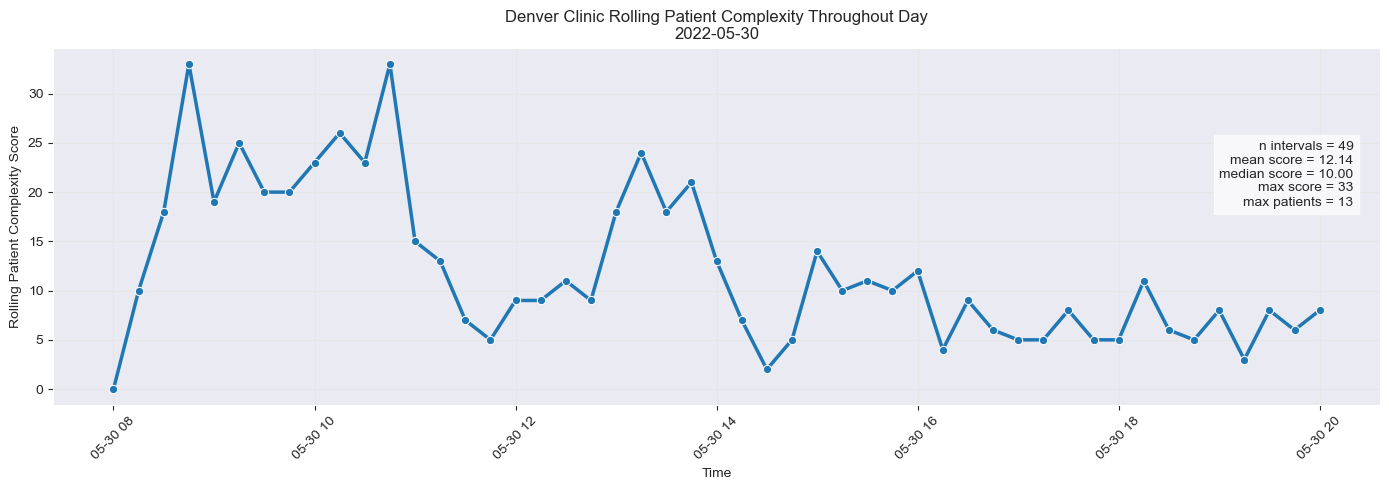

In [35]:
# Select specific Denver clinic date
selected_date = '2022-05-30'

# Filter rolling complexity data
denver_day = rolling_complexity[
    (rolling_complexity['visit_location'] == 'denver') &
    (rolling_complexity['time_interval'].dt.date == pd.to_datetime(selected_date).date())
]


# Set up figure
plt.figure(figsize=(14, 5))

# Plot rolling patient complexity score
sns.lineplot(
    data=denver_day,
    x='time_interval',
    y='rolling_pt_complexity_score',
    marker='o',
    linewidth=2.5
)

# Add summary statistics
summary_text = (
    f"n intervals = {len(denver_day)}\n"
    f"mean score = {denver_day['rolling_pt_complexity_score'].mean():.2f}\n"
    f"median score = {denver_day['rolling_pt_complexity_score'].median():.2f}\n"
    f"max score = {denver_day['rolling_pt_complexity_score'].max():.0f}\n"
    f"max patients = {denver_day['patients_present'].max():.0f}"
)

plt.text(
    0.98,
    0.55,
    summary_text,
    transform=plt.gca().transAxes,
    ha='right',
    va='bottom',
    fontsize=10,
    bbox=dict(
        facecolor='white',
        alpha=0.7
    )
)

# Labels and formatting
plt.title(f'Denver Clinic Rolling Patient Complexity Throughout Day\n{selected_date}')
plt.xlabel('Time')
plt.ylabel('Rolling Patient Complexity Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 6b. Explore the rolling complexity scores daily dynamics to determine appropriate threshold to trigger flag in TecNav algorithm.

In [36]:
rolling_complexity['rolling_pt_complexity_score'].describe()

count    7595.000000
mean        9.517709
std         6.451949
min         0.000000
25%         5.000000
50%         9.000000
75%        13.000000
max        42.000000
Name: rolling_pt_complexity_score, dtype: float64

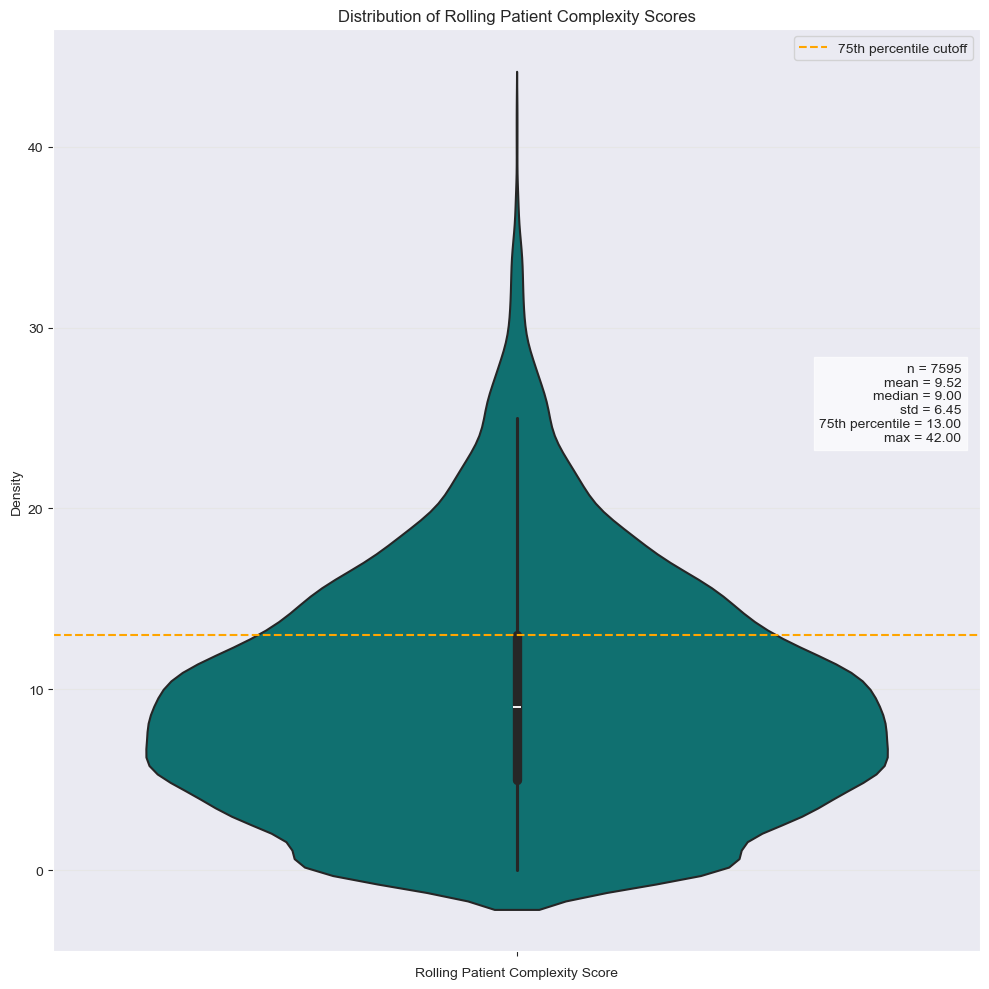

In [37]:
# Set up figure
plt.figure(figsize=(10, 10))

# Violin plot of rolling complexity score distribution
sns.violinplot(
    data=rolling_complexity,
    y='rolling_pt_complexity_score',
    inner='box',
    linewidth=1.5,
    color='teal'
)

# Summary statistics
summary_text = (
    f"n = {rolling_complexity['rolling_pt_complexity_score'].count()}\n"
    f"mean = {rolling_complexity['rolling_pt_complexity_score'].mean():.2f}\n"
    f"median = {rolling_complexity['rolling_pt_complexity_score'].median():.2f}\n"
    f"std = {rolling_complexity['rolling_pt_complexity_score'].std():.2f}\n"
    f"75th percentile = {rolling_complexity['rolling_pt_complexity_score'].quantile(0.75):.2f}\n"
    f"max = {rolling_complexity['rolling_pt_complexity_score'].max():.2f}"
)

plt.text(
    0.98,
    0.55,
    summary_text,
    transform=plt.gca().transAxes,
    ha='right',
    va='bottom',
    fontsize=10,
    bbox=dict(
        facecolor='white',
        alpha=0.7
    )
)

# Add 75th percentile threshold
plt.axhline(
    rolling_complexity['rolling_pt_complexity_score'].quantile(0.75),
    linestyle='--',
    color='orange',
    label='75th percentile cutoff'
)

plt.title('Distribution of Rolling Patient Complexity Scores')
plt.xlabel('Rolling Patient Complexity Score')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
# Calculate complexity score thresholds across all clinic intervals
complexity_thresholds = {
    '75th_percentile': rolling_complexity['rolling_pt_complexity_score'].quantile(0.75),
    '90th_percentile': rolling_complexity['rolling_pt_complexity_score'].quantile(0.90),
    '95th_percentile': rolling_complexity['rolling_pt_complexity_score'].quantile(0.95)
}

complexity_thresholds

{'75th_percentile': 13.0, '90th_percentile': 18.0, '95th_percentile': 21.0}

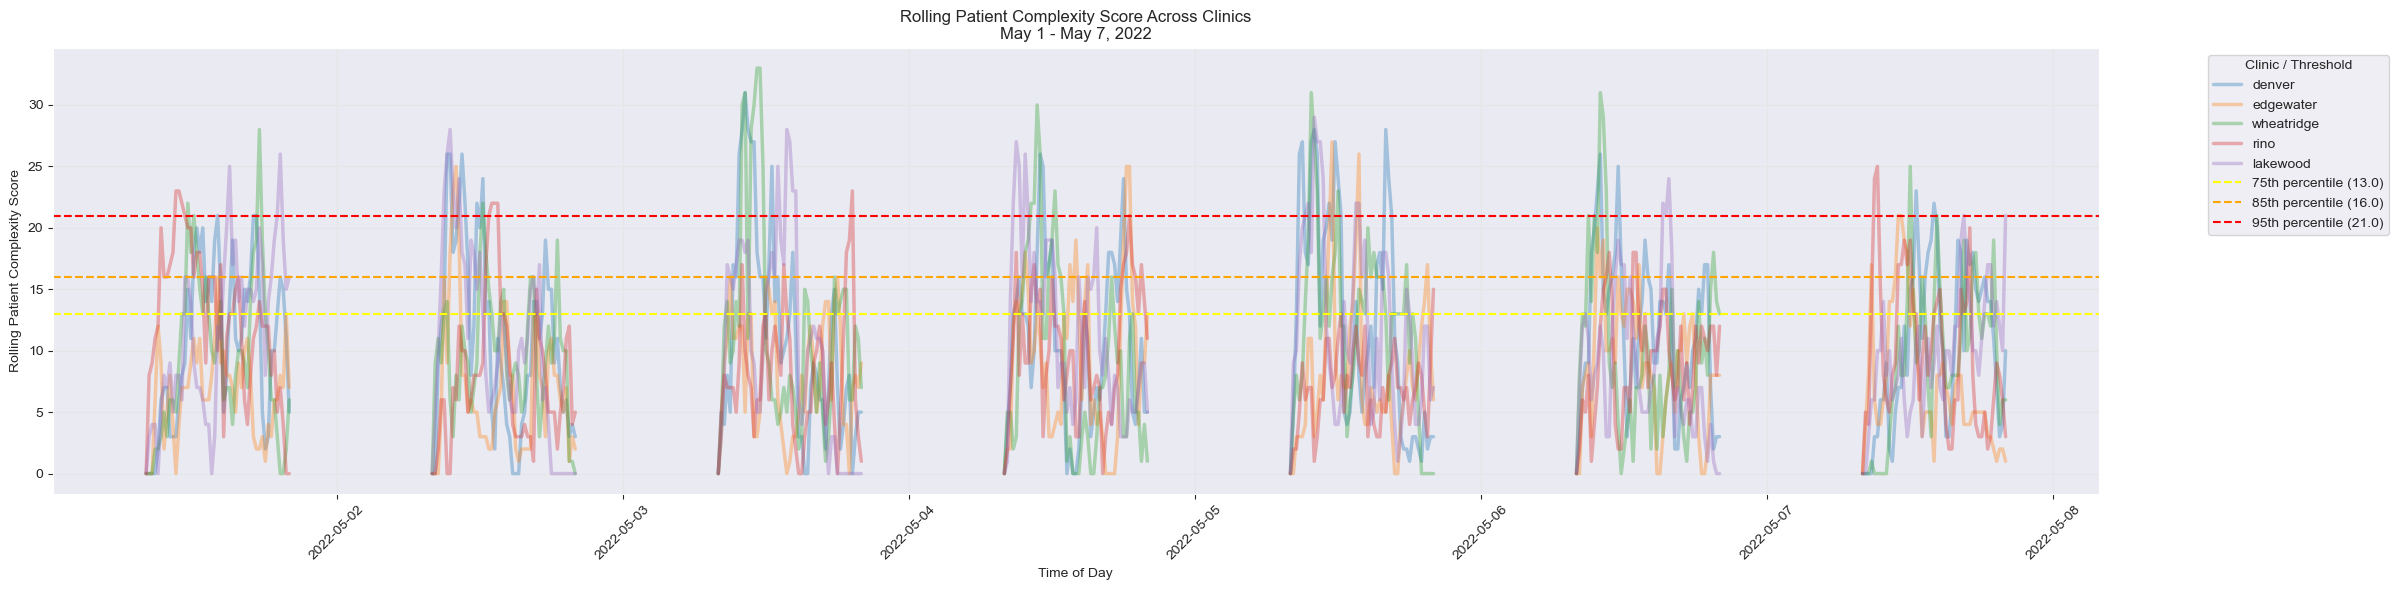

In [39]:
# Calculate complexity score percentile thresholds
complexity_percentiles = {
    '75th': rolling_complexity['rolling_pt_complexity_score'].quantile(0.75),
    '85th': rolling_complexity['rolling_pt_complexity_score'].quantile(0.85),
    '95th': rolling_complexity['rolling_pt_complexity_score'].quantile(0.95)
}
# Define threshold colors
percentile_colors = {
    '75th': 'yellow',
    '85th': 'orange',
    '95th': 'red'
}


# Filter rolling complexity data for one week
selected_week = rolling_complexity[
    (rolling_complexity['time_interval'].dt.date >= pd.to_datetime('2022-05-01').date()) &
    (rolling_complexity['time_interval'].dt.date <= pd.to_datetime('2022-05-07').date())
]


# Set up figure
plt.figure(figsize=(24, 6))

# Plot every clinic-day rolling complexity curve
sns.lineplot(
    data=selected_week,
    x='time_interval',
    y='rolling_pt_complexity_score',
    hue='visit_location',
    units=(
        selected_week['visit_location'].astype(str) + '_' +
        selected_week['time_interval'].dt.date.astype(str)
    ),
    estimator=None,
    alpha=0.35,
    linewidth=2.5
)

# Add complexity threshold lines
for percentile, score in complexity_percentiles.items():
    plt.axhline(
        score,
        linestyle='--',
        linewidth=1.5,
        color=percentile_colors[percentile],
        label=f'{percentile} percentile ({score:.1f})'
    )

# Labels and formatting
plt.title('Rolling Patient Complexity Score Across Clinics\nMay 1 - May 7, 2022')
plt.xlabel('Time of Day')
plt.ylabel('Rolling Patient Complexity Score')
plt.xticks(rotation=45)
plt.legend(title='Clinic / Threshold', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Based on the explorations of the new target feature, it seems that 85% threshold of a rolling complexity score of 16 seems to be a good threshold to trigger navigation moves (or at least serve as a flag for the ML model to predict if will increase or decrease before triggering the flag). This is because most clinics experience a higher score at some point during the day, which would round out to about 1-2 transfers a day. This is a reasonable target based on a typical navigation workload in urgent care settings.

---
---
## 7: Export

---

In [40]:
pt_visit_records.to_pickle(BASE_DIR / 'pickled_objects/' / 'pt_visit_records_v2.pkl')
rolling_complexity.to_pickle(BASE_DIR / 'pickled_objects/' / 'rolling_target_v2.pkl')